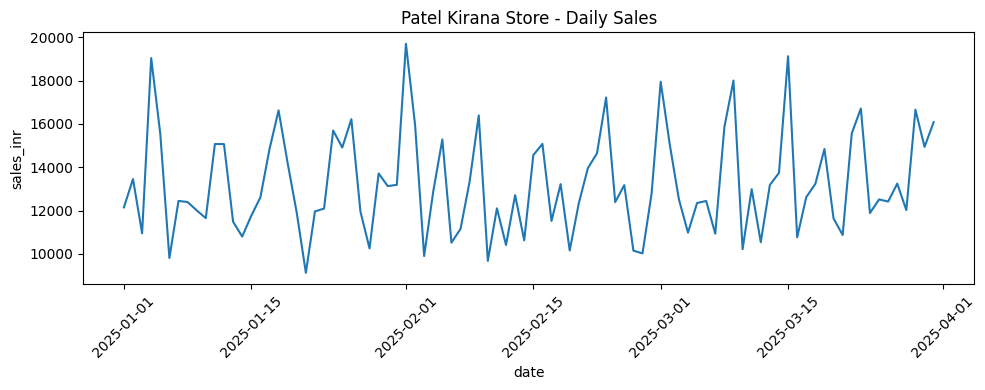

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

dates = pd.date_range('2025-01-01', periods=90)
is_weekend = dates.dayofweek >= 5
day_type = np.where(is_weekend, 'Weekend', 'Weekday')

sales = np.where(
    is_weekend,
    np.random.normal(16000, 2000, size=90),
    np.random.normal(12000, 1500, size=90)
)
sales = np.round(sales).astype(int)

df = pd.DataFrame({
    'date': dates,
    'day_type': day_type,
    'sales_inr': sales
})

df.to_csv('kirana_sales.csv', index=False)

plt.figure(figsize=(10, 4))
sns.lineplot(data=df, x='date', y='sales_inr')
plt.title('Patel Kirana Store - Daily Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

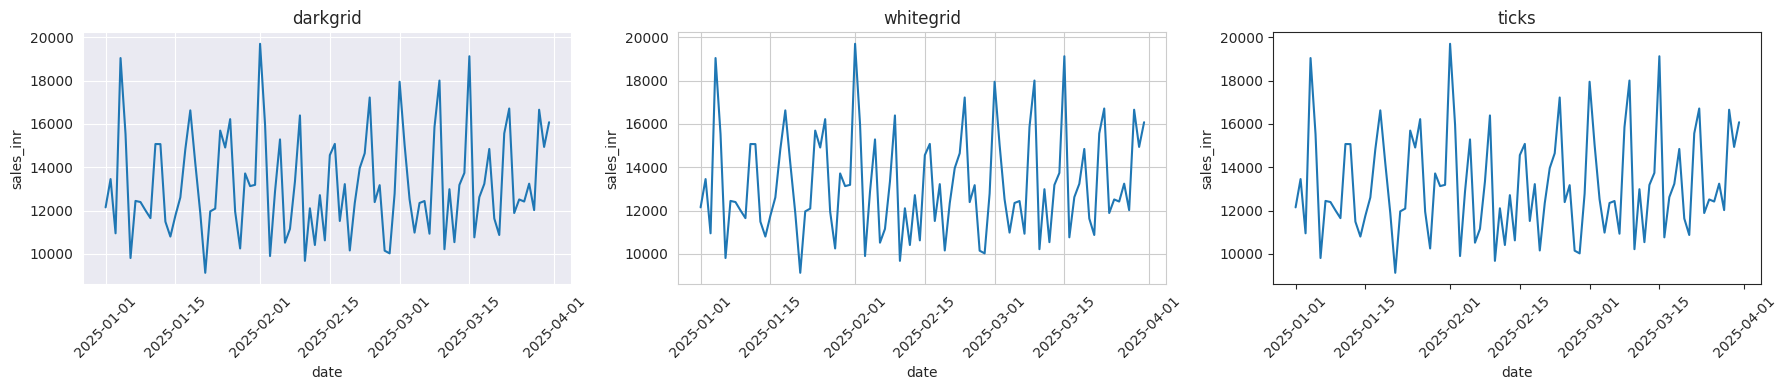

In [2]:
themes = ['darkgrid', 'whitegrid', 'ticks']
fig = plt.figure(figsize=(18, 4))

for i, theme in enumerate(themes, start=1):
    with sns.axes_style(theme):
        ax = fig.add_subplot(1, 3, i)
        sns.lineplot(data=df, x='date', y='sales_inr', ax=ax)
        ax.set_title(theme)
        ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
fig.savefig('kirana_themes.png', bbox_inches='tight')
plt.show()

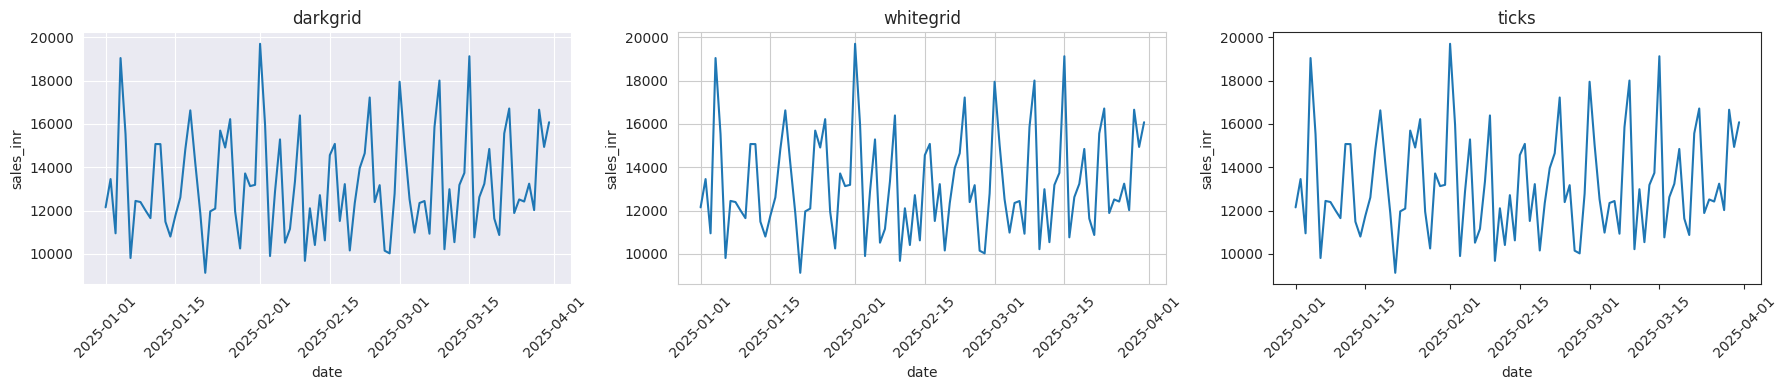

In [3]:
themes = ['darkgrid', 'whitegrid', 'ticks']
fig = plt.figure(figsize=(18, 4))

for i, theme in enumerate(themes, start=1):
    with sns.axes_style(theme):
        ax = fig.add_subplot(1, 3, i)
        sns.lineplot(data=df, x='date', y='sales_inr', ax=ax)
        ax.set_title(theme)
        ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
fig.savefig('kirana_themes.png', bbox_inches='tight')
plt.show()

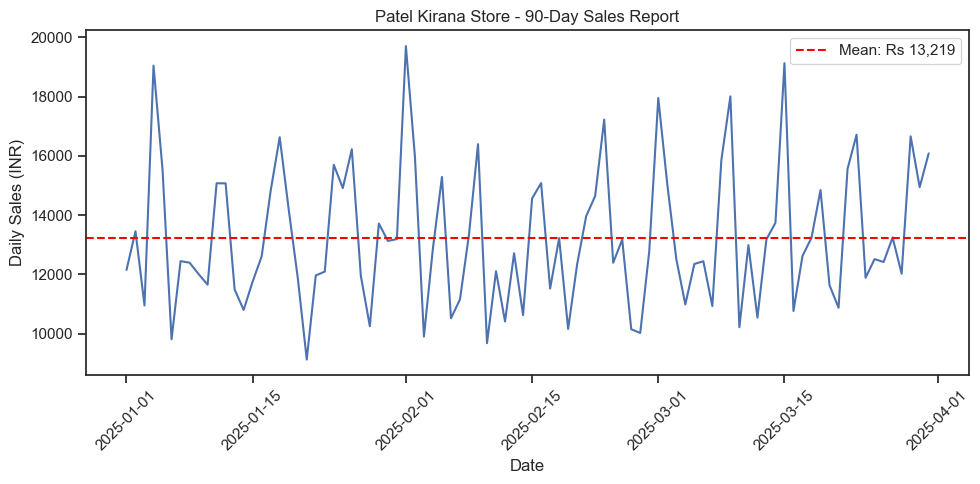

In [4]:
sns.set_theme(style='ticks')

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=df, x='date', y='sales_inr', ax=ax)

mean_sales = df['sales_inr'].mean()
ax.axhline(mean_sales, color='red', linestyle='--', label=f'Mean: Rs {mean_sales:,.0f}')

ax.set_title('Patel Kirana Store - 90-Day Sales Report')
ax.set_xlabel('Date')
ax.set_ylabel('Daily Sales (INR)')
plt.xticks(rotation=45)
ax.legend()
plt.tight_layout()

fig.savefig('kirana_sales_report.png', dpi=150, bbox_inches='tight')
plt.show()

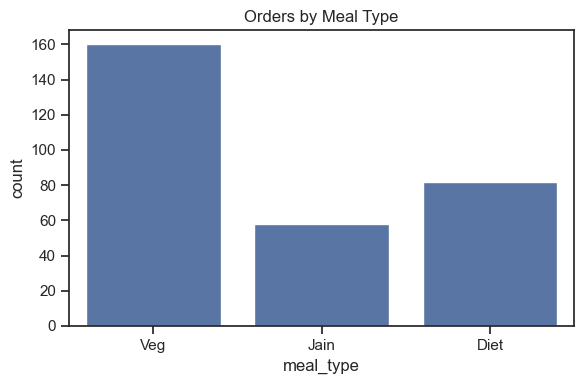

In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

n = 300
areas = ['Satellite', 'Bopal', 'Maninagar', 'Naranpura', 'Vastrapur']
meal_types = ['Veg', 'Jain', 'Diet']
plan_types = ['Trial', 'Weekly', 'Monthly']

df = pd.DataFrame({
    'order_id': range(1, n + 1),
    'area': np.random.choice(areas, size=n),
    'meal_type': np.random.choice(meal_types, size=n, p=[0.5, 0.2, 0.3]),
    'plan_type': np.random.choice(plan_types, size=n),
    'quantity': np.random.randint(1, 5, size=n)
})

price_map = {'Veg': 90, 'Jain': 100, 'Diet': 140}
df['amount_inr'] = df['quantity'] * df['meal_type'].map(price_map)

df.to_csv('tiffin_orders.csv', index=False)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='meal_type', order=['Veg', 'Jain', 'Diet'])
plt.title('Orders by Meal Type')
plt.tight_layout()
plt.show()

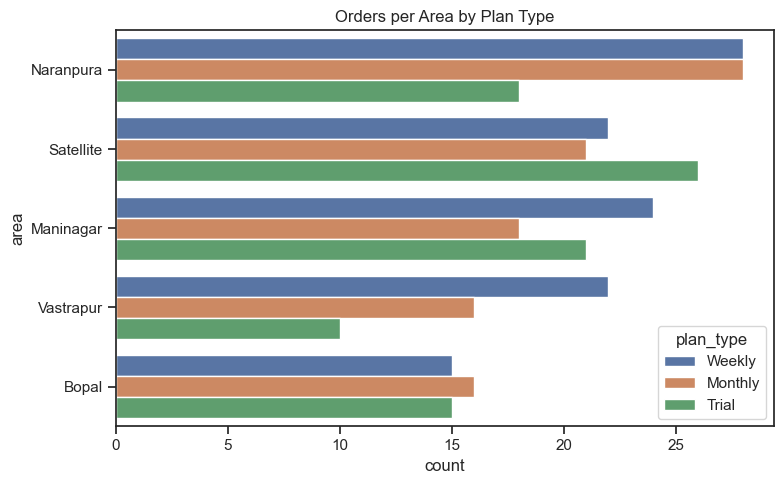

In [6]:
area_order = df['area'].value_counts().index

plt.figure(figsize=(8, 5))
sns.countplot(data=df, y='area', hue='plan_type', order=area_order)
plt.title('Orders per Area by Plan Type')
plt.tight_layout()
plt.savefig('tiffin_area_plans.png', bbox_inches='tight')
plt.show()

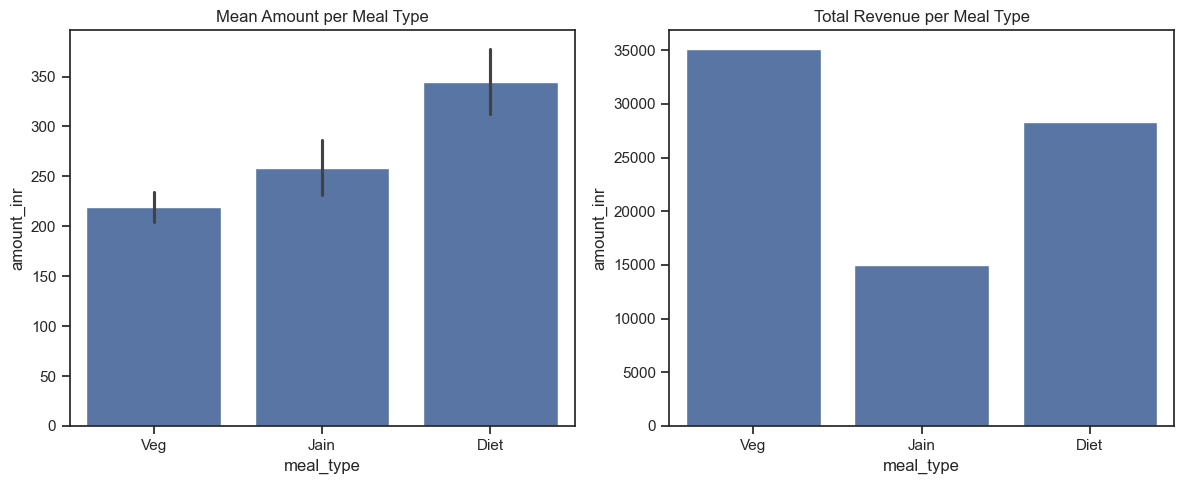

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=df, x='meal_type', y='amount_inr', order=['Veg', 'Jain', 'Diet'], ax=axes[0])
axes[0].set_title('Mean Amount per Meal Type')

sns.barplot(data=df, x='meal_type', y='amount_inr', order=['Veg', 'Jain', 'Diet'],
            estimator='sum', errorbar=None, ax=axes[1])
axes[1].set_title('Total Revenue per Meal Type')

plt.tight_layout()
fig.savefig('tiffin_mean_vs_sum.png', bbox_inches='tight')
plt.show()

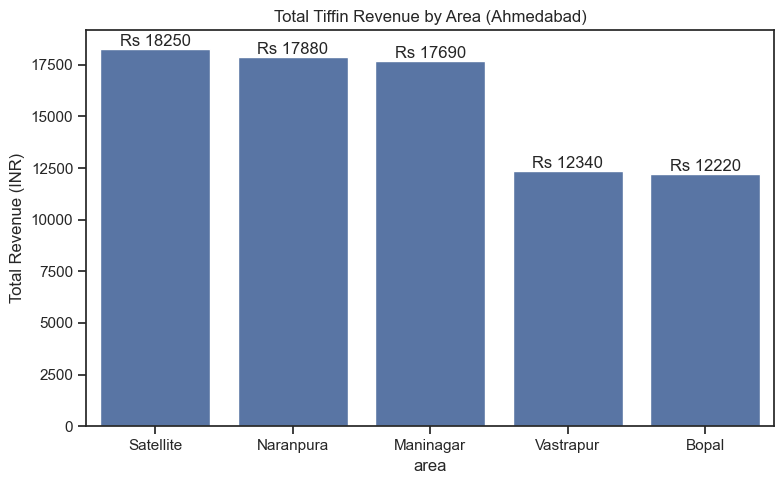

In [8]:
rev_order = df.groupby('area')['amount_inr'].sum().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=df, x='area', y='amount_inr', order=rev_order,
            estimator='sum', errorbar=None, ax=ax)

ax.bar_label(ax.containers[0], fmt='Rs %.0f')
ax.set_title('Total Tiffin Revenue by Area (Ahmedabad)')
ax.set_ylabel('Total Revenue (INR)')
plt.tight_layout()
fig.savefig('tiffin_revenue_by_area.png', bbox_inches='tight')
plt.show()

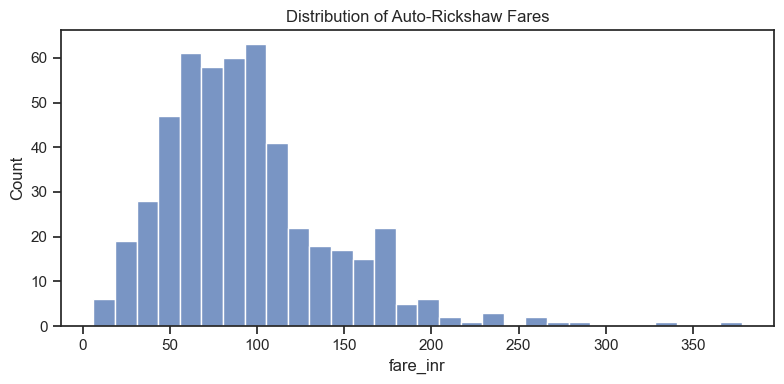

In [9]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

n = 500
time_slot = np.random.choice(['Morning', 'Afternoon', 'Night'], size=n)
distance_km = np.round(np.clip(np.random.gamma(2, 2, n), 0.5, 25), 1)

base_fare = 30 + 13 * distance_km + np.random.normal(0, 15, n)
fare_inr = np.where(time_slot == 'Night', base_fare * 1.25, base_fare)
fare_inr = np.round(fare_inr, 2)

df = pd.DataFrame({
    'trip_id': range(1, n + 1),
    'time_slot': time_slot,
    'distance_km': distance_km,
    'fare_inr': fare_inr
})

df.to_csv('rickshaw_trips.csv', index=False)

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='fare_inr', bins=30)
plt.title('Distribution of Auto-Rickshaw Fares')
plt.tight_layout()
plt.show()

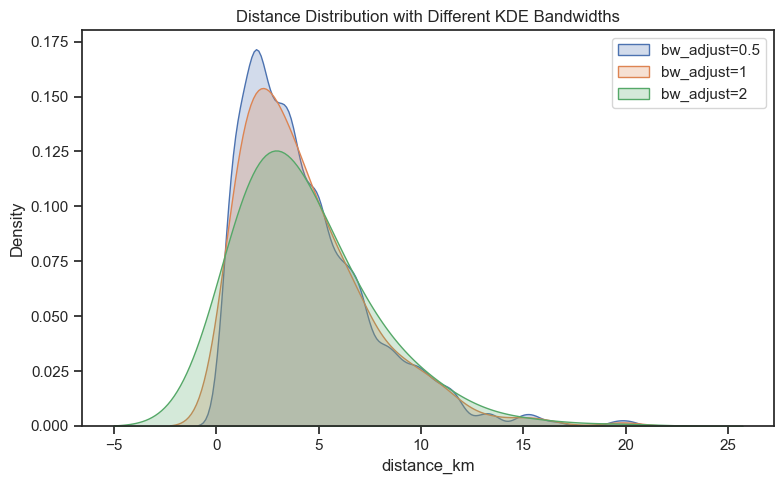

In [10]:
plt.figure(figsize=(8, 5))

for bw in [0.5, 1, 2]:
    sns.kdeplot(data=df, x='distance_km', bw_adjust=bw, fill=True, label=f'bw_adjust={bw}')

plt.title('Distance Distribution with Different KDE Bandwidths')
plt.legend()
plt.tight_layout()
plt.savefig('rickshaw_bandwidth.png', bbox_inches='tight')
plt.show()

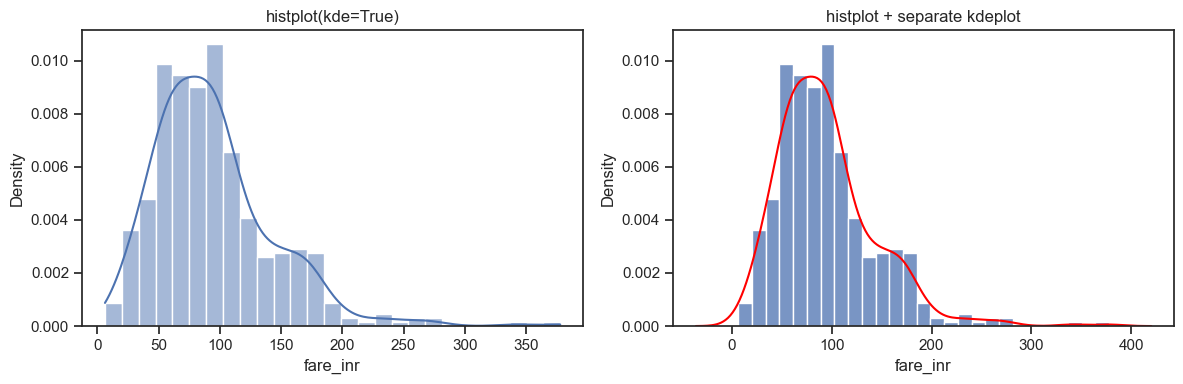

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x='fare_inr', stat='density', kde=True, ax=axes[0])
axes[0].set_title('histplot(kde=True)')

sns.histplot(data=df, x='fare_inr', stat='density', ax=axes[1])
sns.kdeplot(data=df, x='fare_inr', color='red', ax=axes[1])
axes[1].set_title('histplot + separate kdeplot')

plt.tight_layout()
fig.savefig('rickshaw_hist_kde.png', bbox_inches='tight')
plt.show()

Median Fare per Time Slot:
 time_slot
Afternoon    84.33
Morning      77.54
Night        99.91
Name: fare_inr, dtype: float64


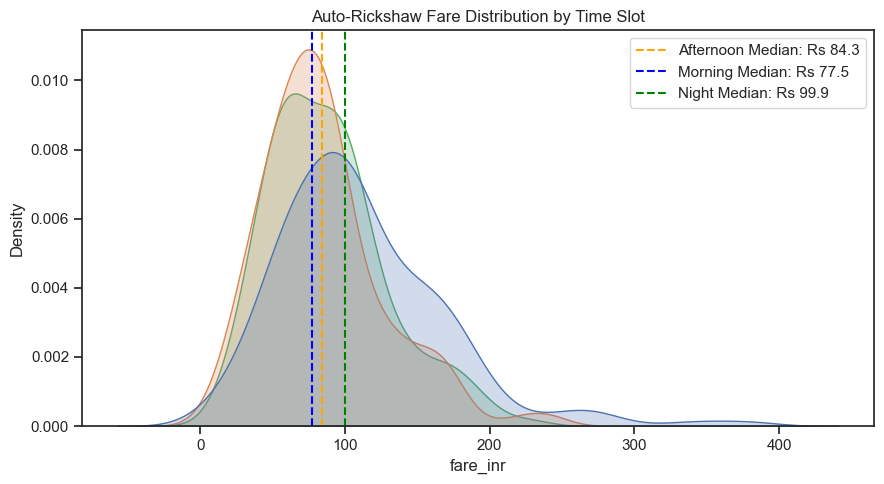

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.kdeplot(data=df, x='fare_inr', hue='time_slot', fill=True, common_norm=False, ax=ax)

medians = df.groupby('time_slot')['fare_inr'].median()
print("Median Fare per Time Slot:\n", medians)

colors = {'Morning': 'blue', 'Afternoon': 'orange', 'Night': 'green'}
for slot, med in medians.items():
    ax.axvline(med, linestyle='--', color=colors[slot], label=f'{slot} Median: Rs {med:.1f}')

ax.set_title('Auto-Rickshaw Fare Distribution by Time Slot')
ax.legend()
plt.tight_layout()
fig.savefig('rickshaw_fare_report.png', bbox_inches='tight')
plt.show()

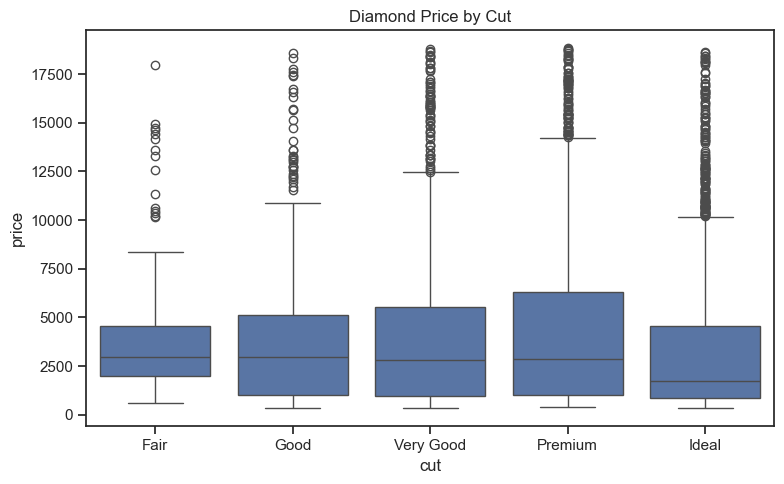

In [13]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

diamonds = sns.load_dataset('diamonds')
df = diamonds.sample(n=5000, random_state=42).copy()
df.to_csv('diamonds_sample.csv', index=False)

cut_order = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='cut', y='price', order=cut_order)
plt.title('Diamond Price by Cut')
plt.tight_layout()
plt.savefig('diamonds_box_price.png', bbox_inches='tight')
plt.show()

In [14]:
q1 = df.groupby('cut', observed=False)['price'].transform(lambda s: s.quantile(0.25))
q3 = df.groupby('cut', observed=False)['price'].transform(lambda s: s.quantile(0.75))
iqr = q3 - q1

df['price_outlier'] = (df['price'] < (q1 - 1.5 * iqr)) | (df['price'] > (q3 + 1.5 * iqr))

raw_outliers = df.groupby('cut', observed=False)['price_outlier'].sum()
print("Outliers per cut (raw price):\n", raw_outliers)

df.to_csv('diamonds_flagged.csv', index=False)

Outliers per cut (raw price):
 cut
Ideal        142
Premium       81
Very Good     68
Good          32
Fair          15
Name: price_outlier, dtype: int64


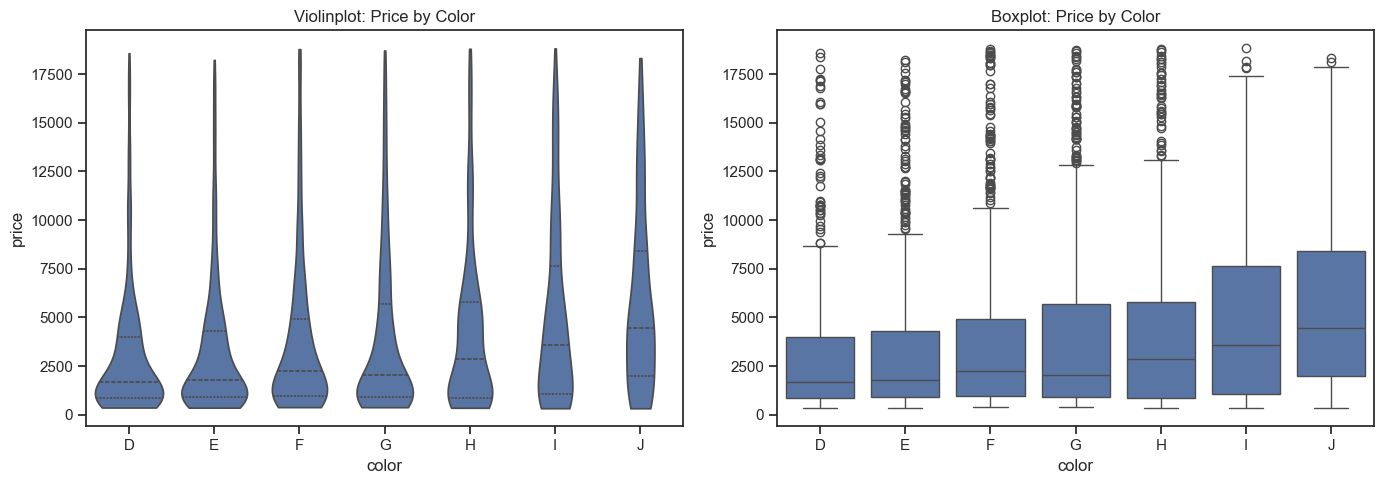

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.violinplot(data=df, x='color', y='price', inner='quartile', cut=0, ax=axes[0])
axes[0].set_title('Violinplot: Price by Color')

sns.boxplot(data=df, x='color', y='price', ax=axes[1])
axes[1].set_title('Boxplot: Price by Color')

plt.tight_layout()
fig.savefig('diamonds_box_vs_violin.png', bbox_inches='tight')
plt.show()

         cut  raw_price_outliers  log_price_outliers
0      Ideal                 142                   0
1    Premium                  81                   0
2  Very Good                  68                   0
3       Good                  32                   0
4       Fair                  15                   1


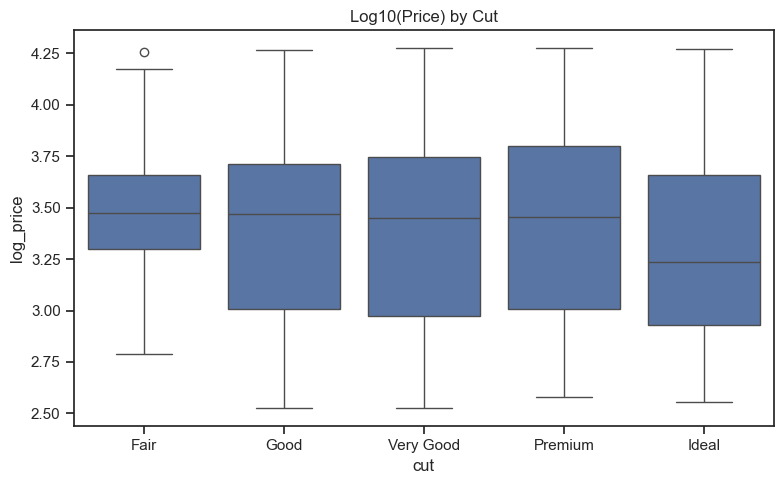

In [16]:
df['log_price'] = np.log10(df['price'])

lq1 = df.groupby('cut', observed=False)['log_price'].transform(lambda s: s.quantile(0.25))
lq3 = df.groupby('cut', observed=False)['log_price'].transform(lambda s: s.quantile(0.75))
liqr = lq3 - lq1

df['log_outlier'] = (df['log_price'] < (lq1 - 1.5 * liqr)) | (df['log_price'] > (lq3 + 1.5 * liqr))
log_outliers = df.groupby('cut', observed=False)['log_outlier'].sum()

outlier_summary = pd.DataFrame({
    'raw_price_outliers': raw_outliers,
    'log_price_outliers': log_outliers
}).reset_index()

print(outlier_summary)
outlier_summary.to_csv('diamonds_outlier_summary.csv', index=False)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='cut', y='log_price', order=cut_order)
plt.title('Log10(Price) by Cut')
plt.tight_layout()
plt.savefig('diamonds_log_box.png', bbox_inches='tight')
plt.show()

Rows remaining: 333


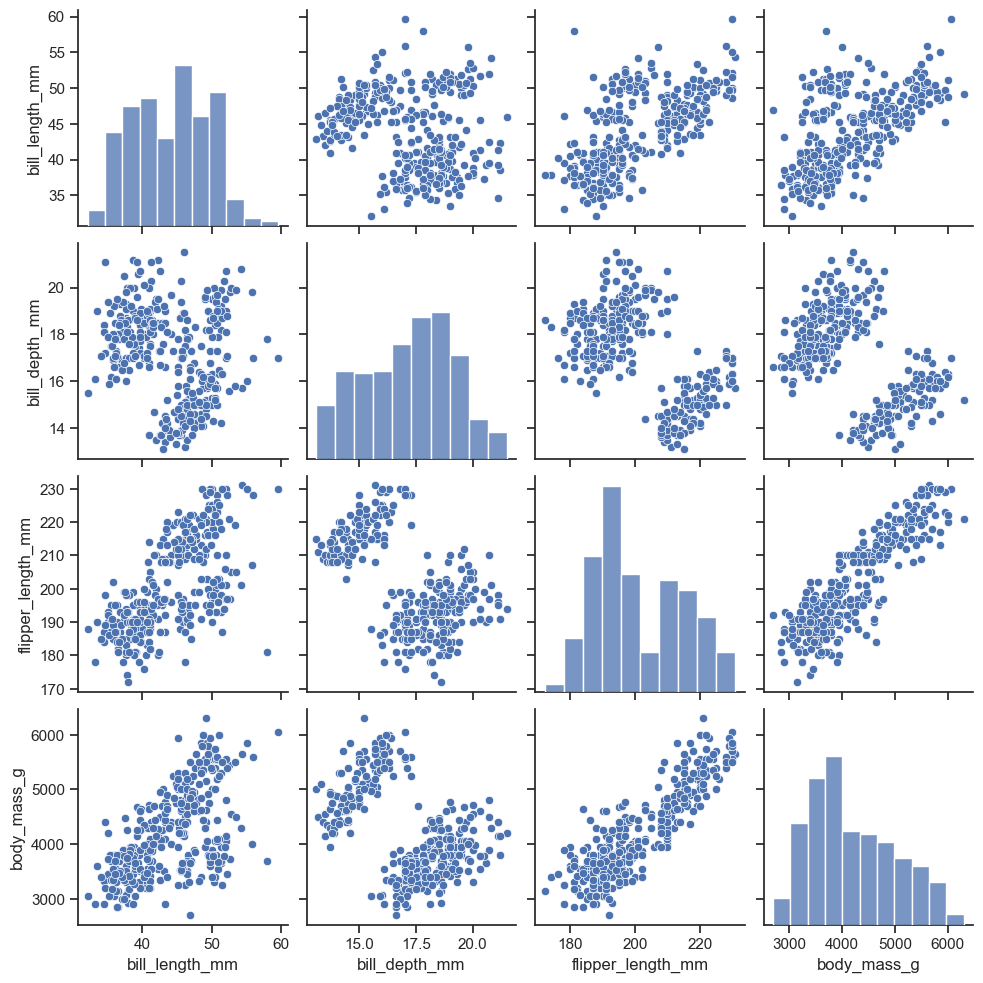

In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset('penguins').dropna().copy()
print("Rows remaining:", len(df))
df.to_csv('penguins_clean.csv', index=False)

num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

g = sns.pairplot(df, vars=num_cols)
g.savefig('penguins_pairplot_basic.png')
plt.show()

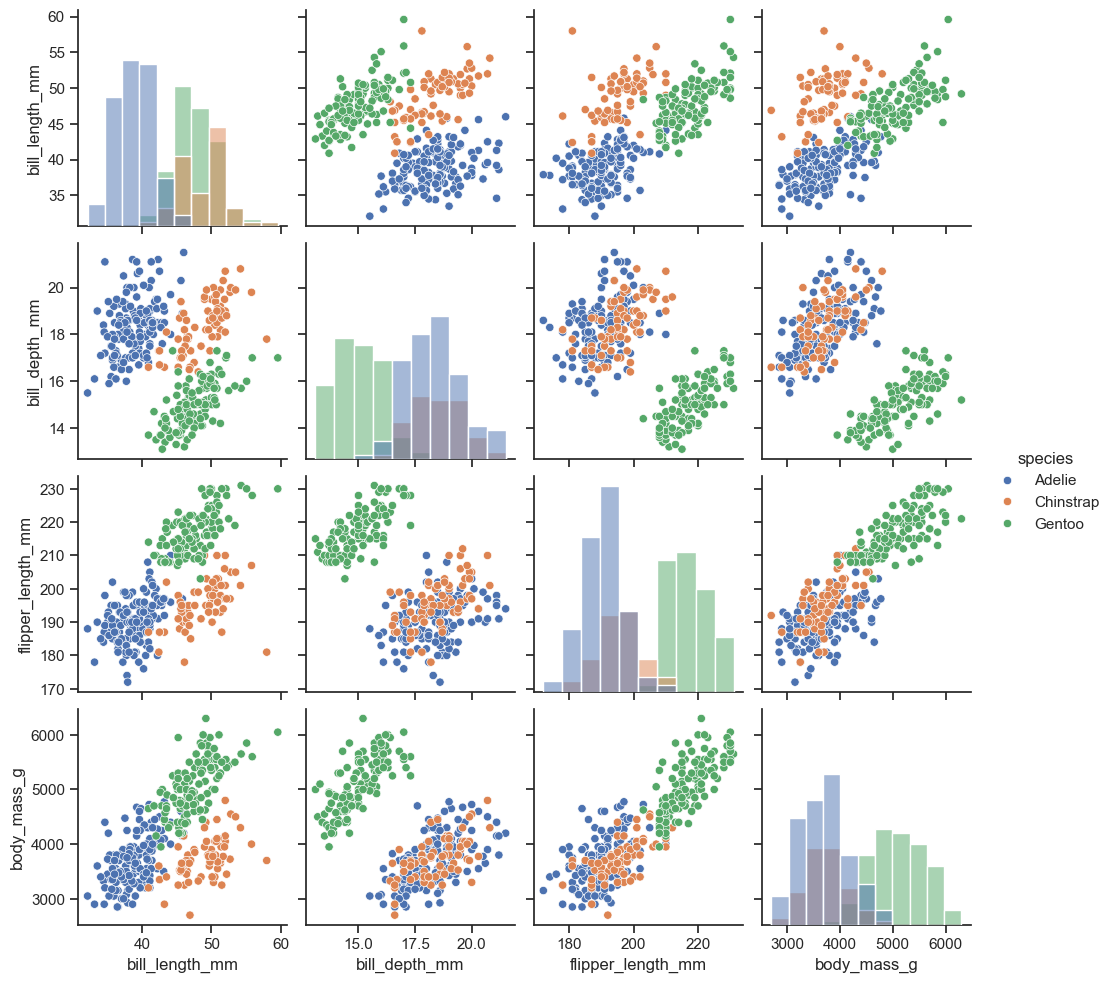

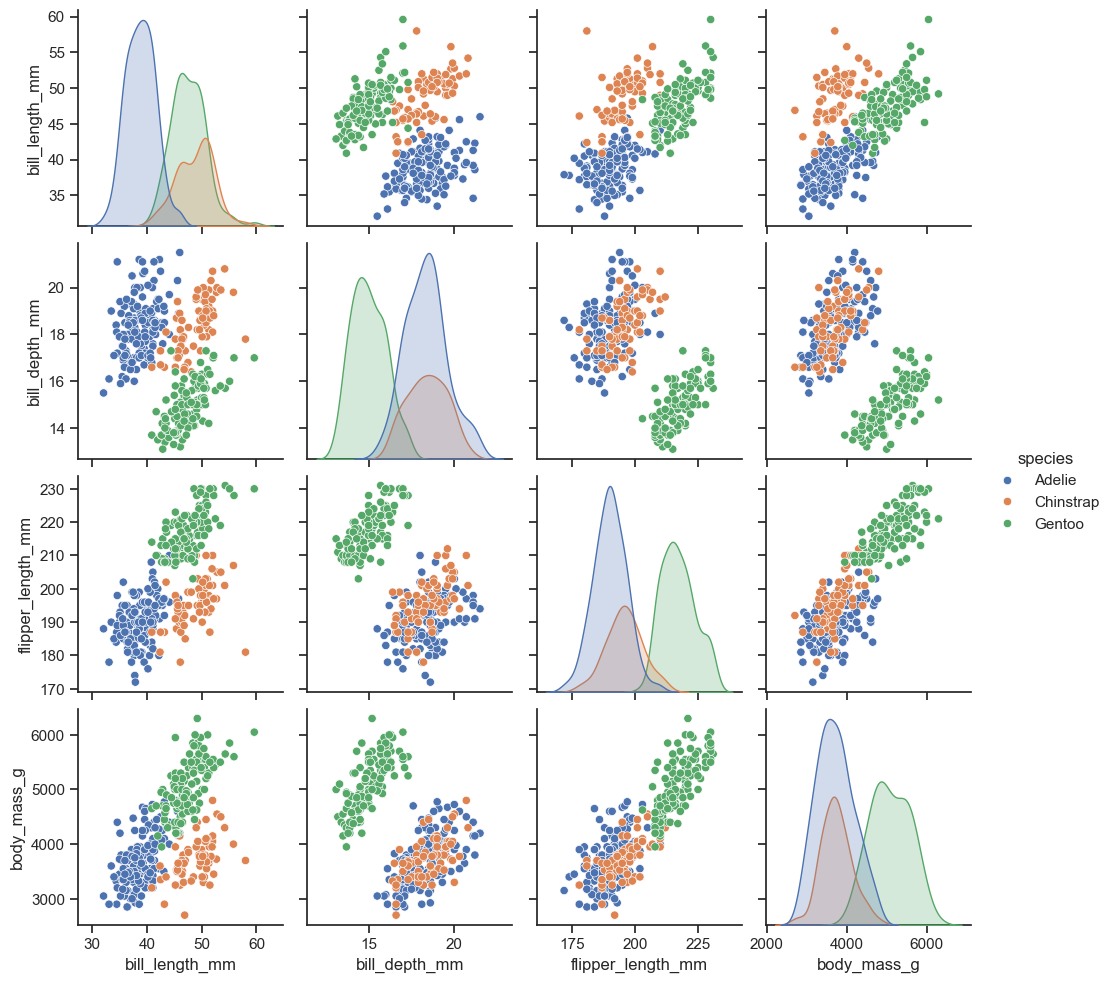

In [18]:
g1 = sns.pairplot(df, vars=num_cols, hue='species', diag_kind='hist')
g1.savefig('penguins_diag_hist.png')
plt.show()

g2 = sns.pairplot(df, vars=num_cols, hue='species', diag_kind='kde')
g2.savefig('penguins_diag_kde.png')
plt.show()

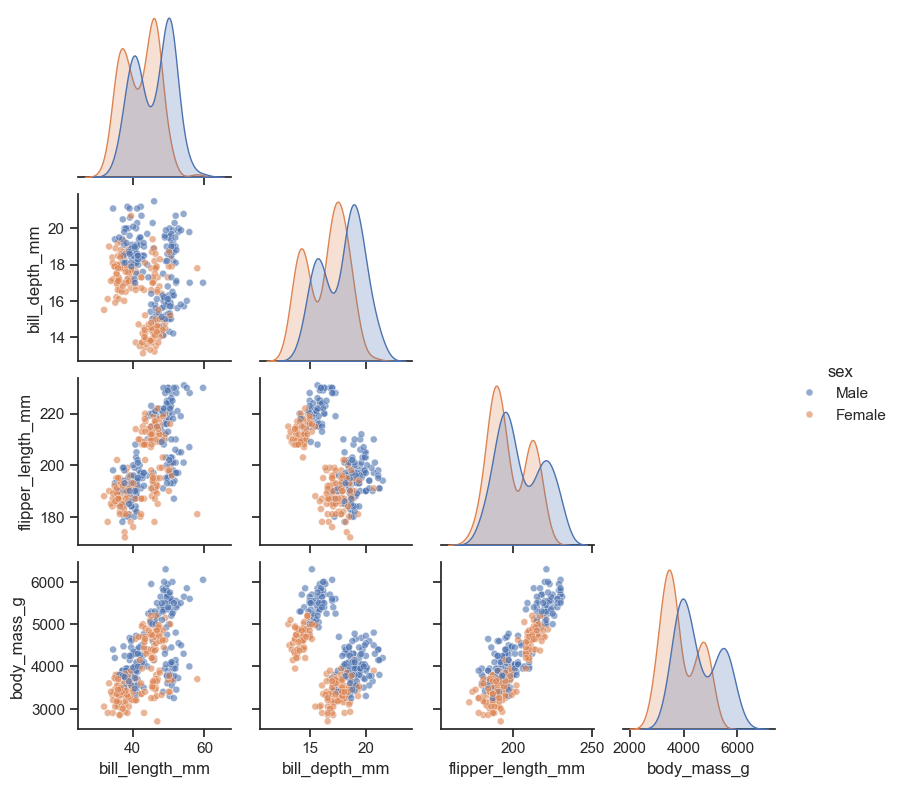

In [19]:
g3 = sns.pairplot(
    df,
    vars=num_cols,
    hue='sex',
    corner=True,
    height=2,
    plot_kws={'alpha': 0.6, 's': 25}
)
g3.savefig('penguins_sex_corner.png')
plt.show()

Mean values per species:
            bill_length_mm  flipper_length_mm  body_mass_g
species                                                  
Adelie              38.82             190.10      3706.16
Chinstrap           48.83             195.82      3733.09
Gentoo              47.57             217.24      5092.44


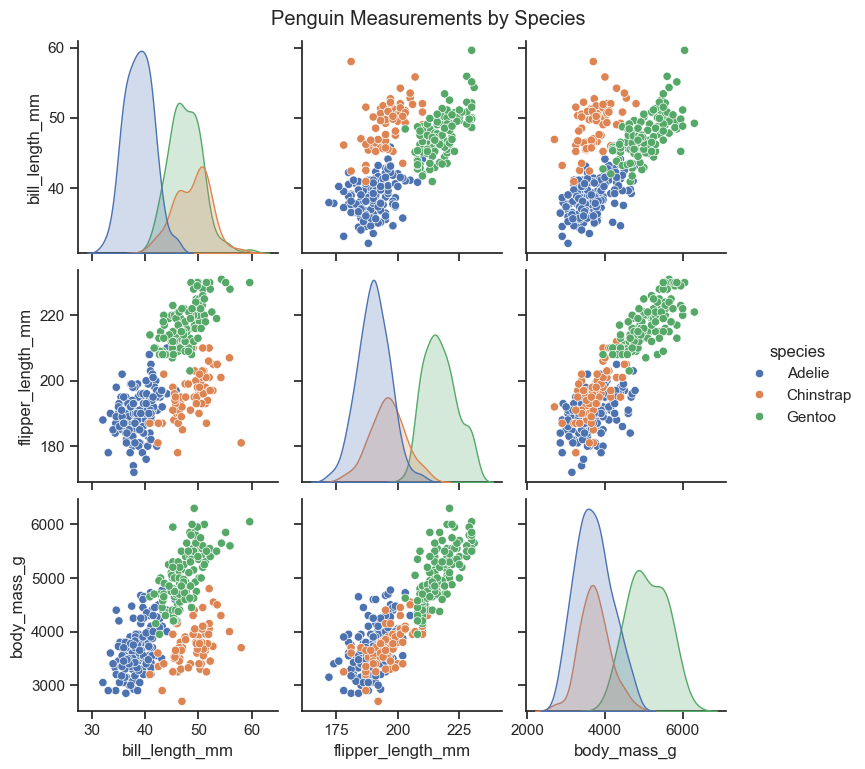

In [20]:
selected_cols = ['bill_length_mm', 'flipper_length_mm', 'body_mass_g']

print("Mean values per species:\n", df.groupby('species')[selected_cols].mean().round(2))

g4 = sns.pairplot(df, vars=selected_cols, hue='species', diag_kind='kde')
g4.figure.suptitle('Penguin Measurements by Species', y=1.02)
g4.savefig('penguins_final_pairplot.png')
plt.show()

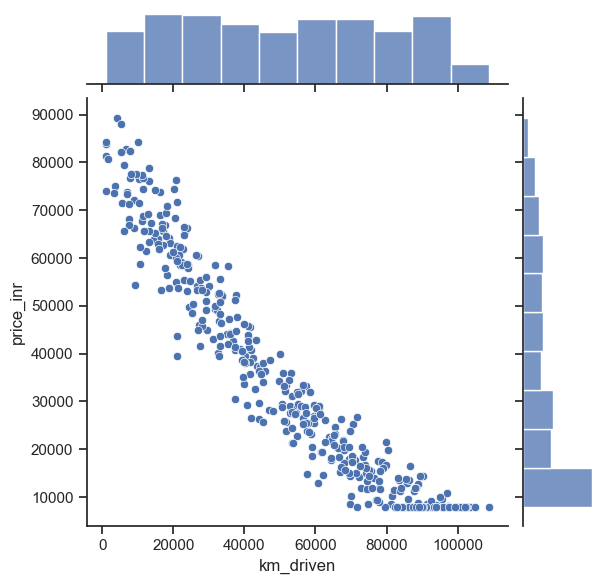

In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

n = 400
age_years = np.random.randint(1, 13, size=n)
ownership = np.random.choice(['First', 'Second'], size=n, p=[0.7, 0.3])

km_driven = age_years * 8000 + np.random.normal(0, 5000, size=n)
km_driven = np.maximum(km_driven, 1000).round().astype(int)

price_inr = 90000 * np.exp(-0.12 * age_years) - 0.2 * km_driven + np.random.normal(0, 4000, size=n)
price_inr = np.where(ownership == 'Second', price_inr * 0.9, price_inr)
price_inr = np.maximum(price_inr, 8000).round().astype(int)

df = pd.DataFrame({
    'age_years': age_years,
    'ownership': ownership,
    'km_driven': km_driven,
    'price_inr': price_inr
})

df.to_csv('two_wheeler_listings.csv', index=False)

g = sns.jointplot(data=df, x='km_driven', y='price_inr', kind='scatter')
plt.show()

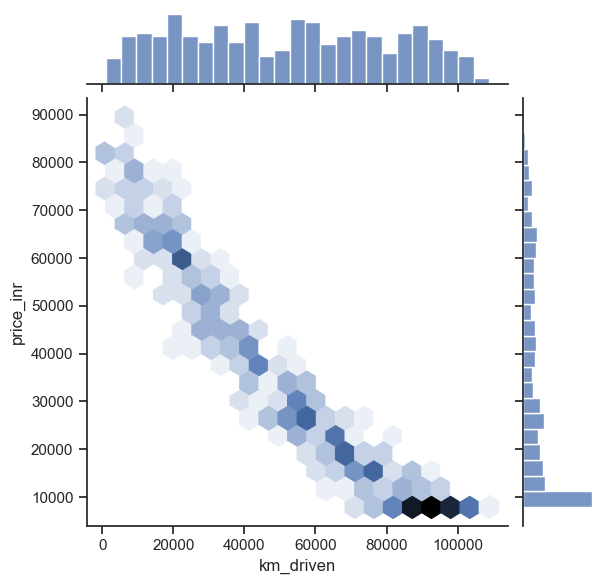

In [22]:
g = sns.jointplot(
    data=df,
    x='km_driven',
    y='price_inr',
    kind='hex',
    joint_kws={'gridsize': 20},
    marginal_kws={'bins': 25}
)
g.savefig('two_wheeler_hex.png')
plt.show()

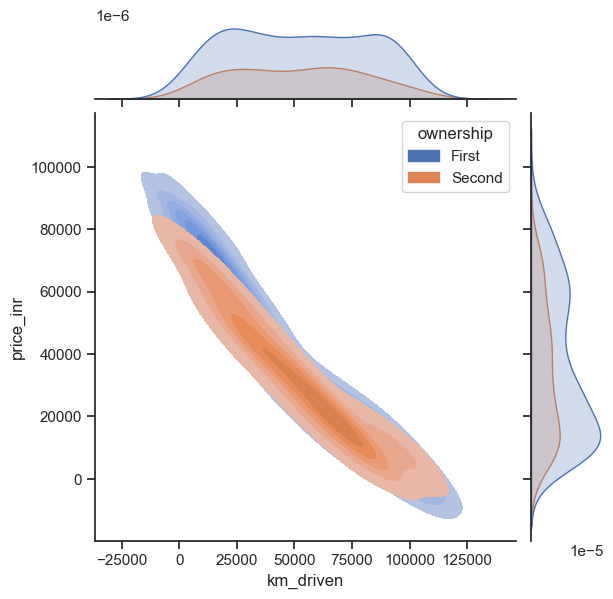

In [23]:
g = sns.jointplot(
    data=df,
    x='km_driven',
    y='price_inr',
    kind='kde',
    fill=True,
    hue='ownership'
)
g.savefig('two_wheeler_kde.png')
plt.show()

Pearson correlation (age_years vs price_inr): -0.965
Pearson correlation (km_driven vs price_inr): -0.958


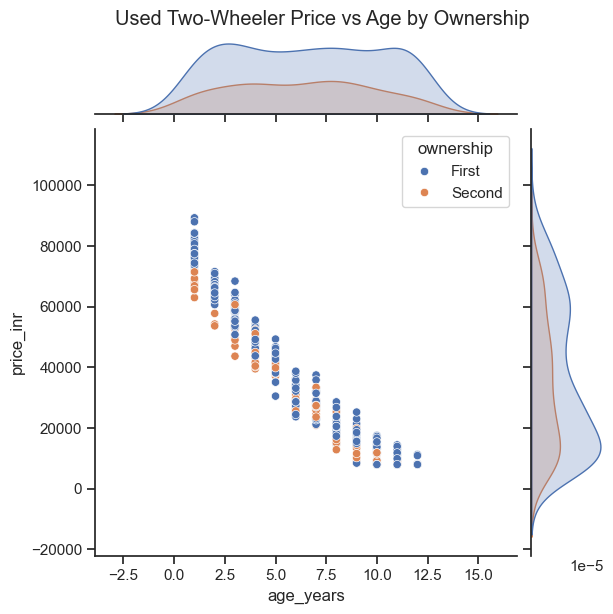

In [24]:
corr_age = df['age_years'].corr(df['price_inr'])
corr_km = df['km_driven'].corr(df['price_inr'])
print(f"Pearson correlation (age_years vs price_inr): {corr_age:.3f}")
print(f"Pearson correlation (km_driven vs price_inr): {corr_km:.3f}")

g = sns.jointplot(
    data=df,
    x='age_years',
    y='price_inr',
    kind='scatter',
    hue='ownership',
    height=6
)
g.figure.suptitle('Used Two-Wheeler Price vs Age by Ownership', y=1.02)
g.savefig('two_wheeler_final_joint.png')
plt.show()

Rows remaining: 392
               mpg  cylinders  displacement  horsepower  weight  acceleration  \
mpg           1.00      -0.78         -0.81       -0.78   -0.83          0.42   
cylinders    -0.78       1.00          0.95        0.84    0.90         -0.50   
displacement -0.81       0.95          1.00        0.90    0.93         -0.54   
horsepower   -0.78       0.84          0.90        1.00    0.86         -0.69   
weight       -0.83       0.90          0.93        0.86    1.00         -0.42   
acceleration  0.42      -0.50         -0.54       -0.69   -0.42          1.00   
model_year    0.58      -0.35         -0.37       -0.42   -0.31          0.29   

              model_year  
mpg                 0.58  
cylinders          -0.35  
displacement       -0.37  
horsepower         -0.42  
weight             -0.31  
acceleration        0.29  
model_year          1.00  


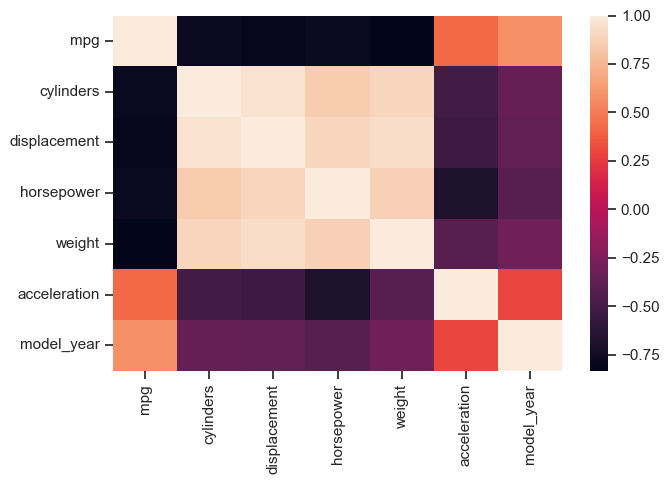

In [25]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset('mpg').dropna().copy()
print("Rows remaining:", len(df))
df.to_csv('mpg_clean.csv', index=False)

corr = df.corr(numeric_only=True)
print(corr.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(corr)
plt.tight_layout()
plt.savefig('mpg_heatmap_basic.png', bbox_inches='tight')
plt.show()

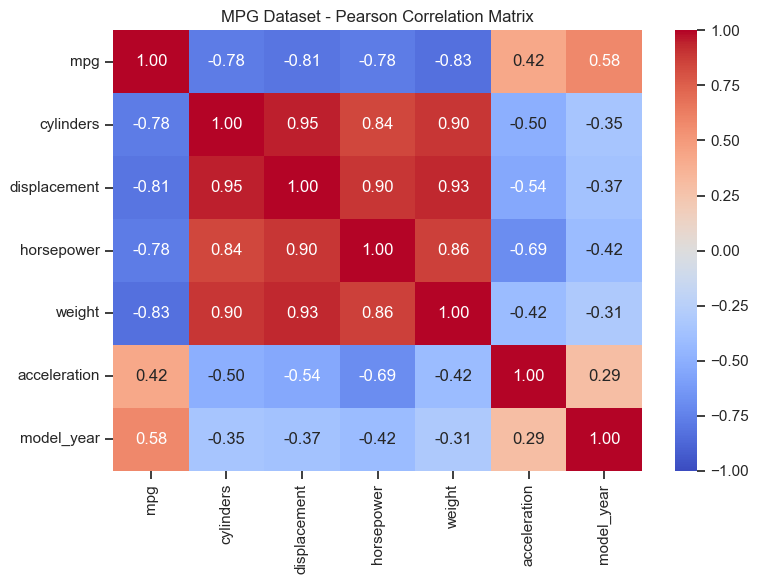

In [26]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('MPG Dataset - Pearson Correlation Matrix')
plt.tight_layout()
plt.savefig('mpg_heatmap_annot.png', bbox_inches='tight')
plt.show()

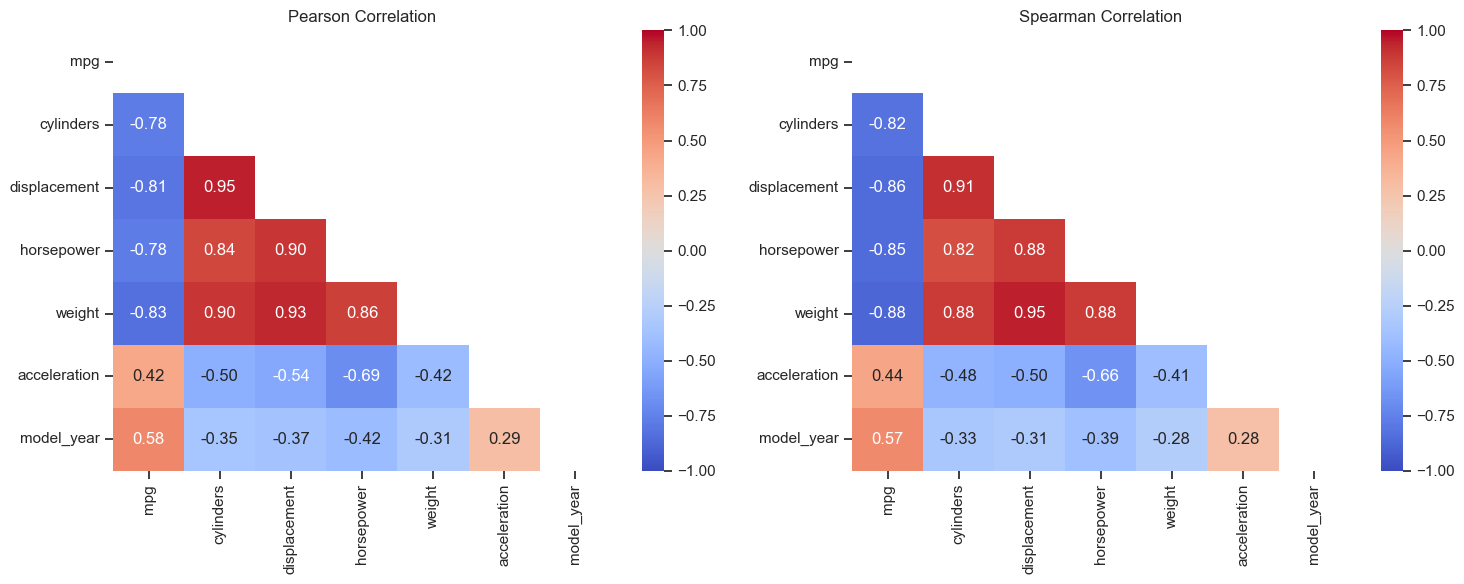

In [27]:
corr_spearman = df.corr(method='spearman', numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Pearson Correlation')

sns.heatmap(corr_spearman, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Spearman Correlation')

plt.tight_layout()
fig.savefig('mpg_pearson_vs_spearman.png', bbox_inches='tight')
plt.show()

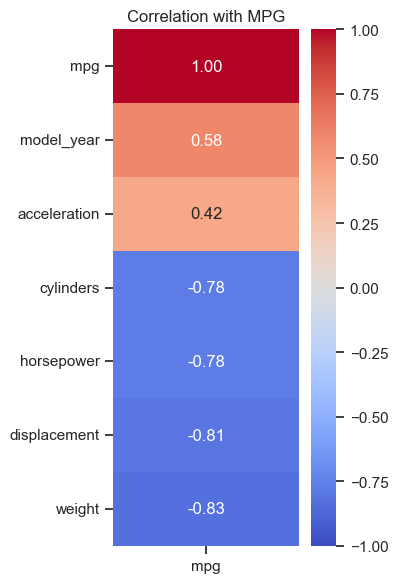

In [28]:
mpg_corr = corr[['mpg']].sort_values('mpg', ascending=False)
mpg_corr.to_csv('mpg_corr_ranked.csv')

plt.figure(figsize=(4, 6))
sns.heatmap(mpg_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation with MPG')
plt.tight_layout()
plt.savefig('mpg_corr_with_mpg.png', bbox_inches='tight')
plt.show()

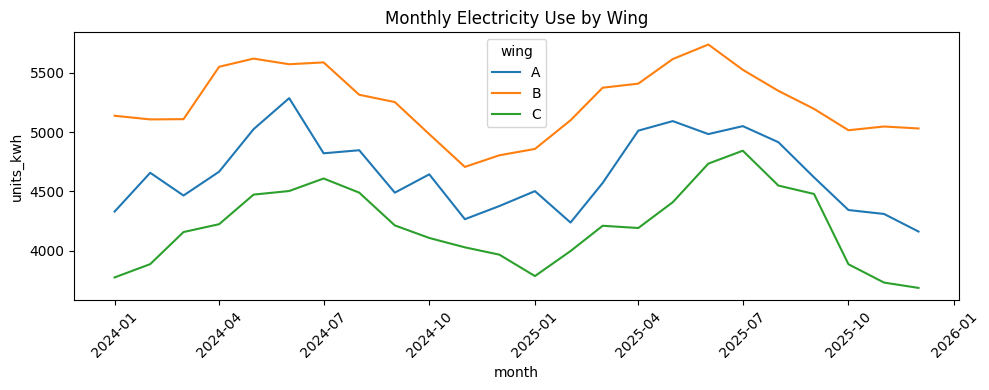

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

months = pd.date_range('2024-01-01', periods=24, freq='MS')
wing_bases = {'A': 3000, 'B': 3600, 'C': 2500}

rows = []
for m in months:
    m_num = m.month
    for wing, base in wing_bases.items():
        temp = 28 + 7 * np.sin(2 * np.pi * (m_num - 3) / 12) + np.random.normal(0, 1)
        units = base + 60 * temp + np.random.normal(0, 120)
        rows.append({
            'month': m,
            'wing': wing,
            'avg_temp_c': round(temp, 1),
            'units_kwh': round(units, 1)
        })

df = pd.DataFrame(rows)
df.to_csv('society_power.csv', index=False)

plt.figure(figsize=(10, 4))
sns.lineplot(data=df, x='month', y='units_kwh', hue='wing')
plt.title('Monthly Electricity Use by Wing')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

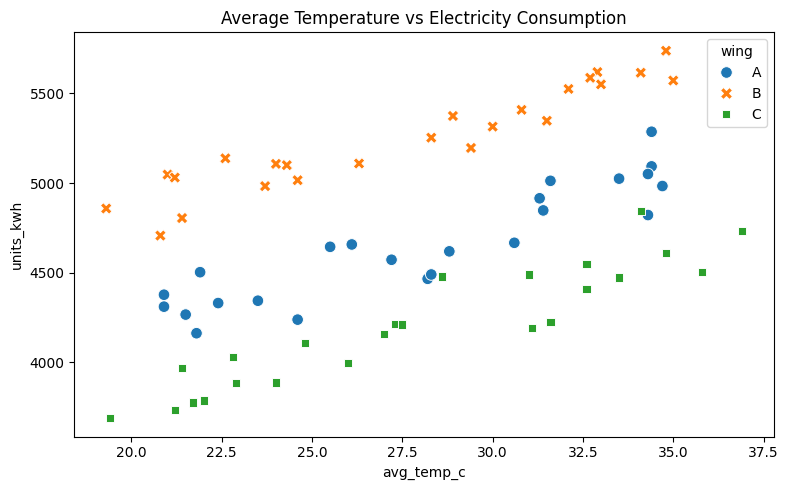

In [3]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='avg_temp_c', y='units_kwh', hue='wing', style='wing', s=70)
plt.title('Average Temperature vs Electricity Consumption')
plt.tight_layout()
plt.savefig('society_temp_scatter.png', bbox_inches='tight')
plt.show()

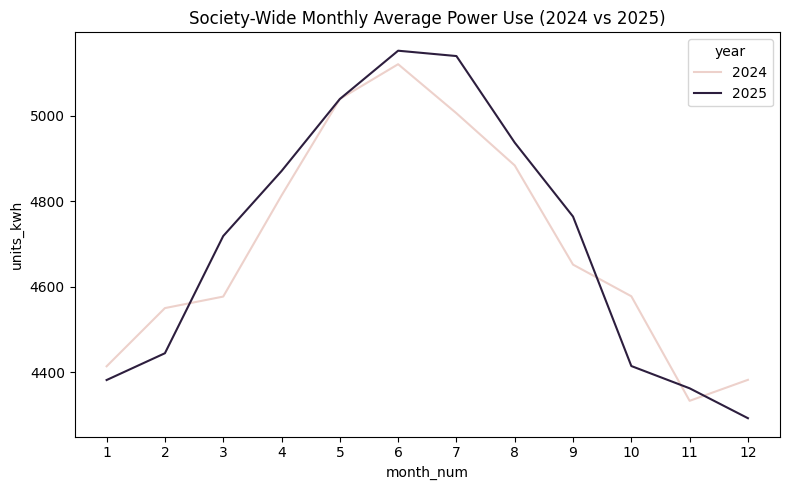

In [4]:
df['month'] = pd.to_datetime(df['month'])
df['year'] = df['month'].dt.year
df['month_num'] = df['month'].dt.month

plt.figure(figsize=(8, 5))
sns.lineplot(data=df, x='month_num', y='units_kwh', hue='year', estimator='mean', errorbar=None)
plt.title('Society-Wide Monthly Average Power Use (2024 vs 2025)')
plt.xticks(range(1, 13))
plt.tight_layout()
plt.savefig('society_year_compare.png', bbox_inches='tight')
plt.show()

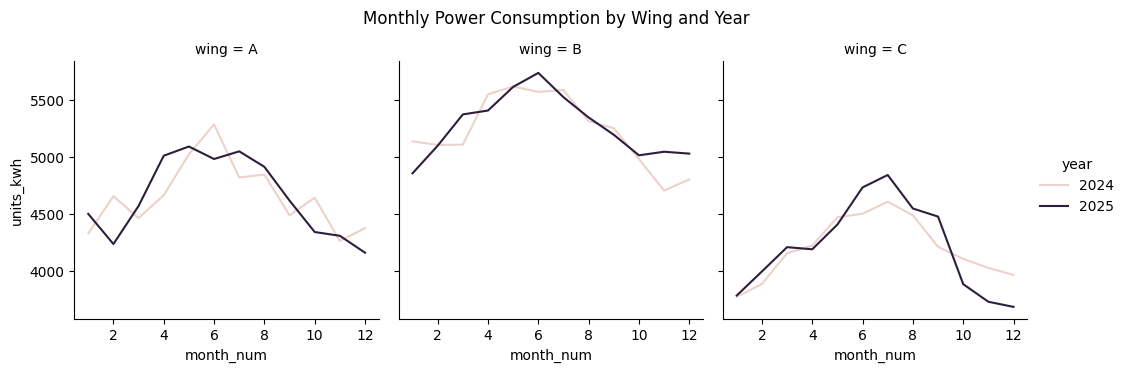

In [5]:
g = sns.relplot(
    data=df,
    x='month_num',
    y='units_kwh',
    hue='year',
    col='wing',
    kind='line',
    height=3.5
)
g.figure.suptitle('Monthly Power Consumption by Wing and Year', y=1.05)
g.savefig('society_power_report.png')
plt.show()

Slope (marks per study hour): 1.614


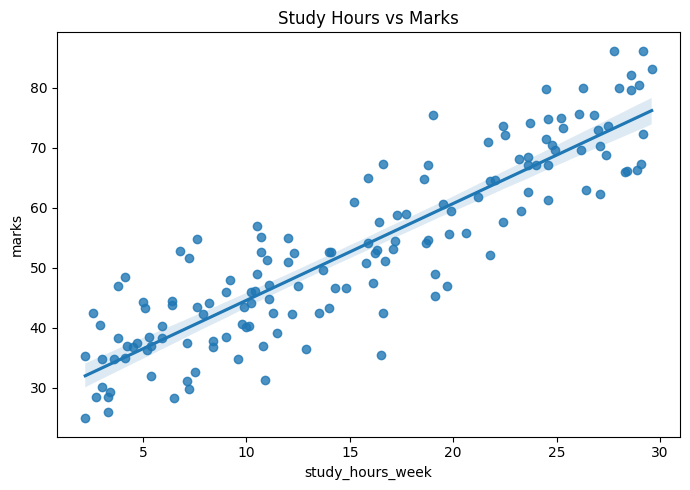

In [6]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

batches = ['Morning'] * 50 + ['Evening'] * 50 + ['Weekend'] * 50
n = 150

study_hours = np.round(np.random.uniform(2, 30, size=n), 1)
attendance = np.random.randint(60, 101, size=n)

offset_map = {'Morning': 3, 'Evening': 0, 'Weekend': -4}
offsets = np.array([offset_map[b] for b in batches])

marks = 25 + 1.6 * study_hours + 0.15 * (attendance - 60) + offsets + np.random.normal(0, 6, size=n)
marks = np.round(np.clip(marks, 0, 100), 1)

df = pd.DataFrame({
    'student_id': range(1, n + 1),
    'batch': batches,
    'study_hours_week': study_hours,
    'attendance_pct': attendance,
    'marks': marks
})

df.to_csv('coaching_marks.csv', index=False)

slope, intercept = np.polyfit(df['study_hours_week'], df['marks'], 1)
print(f"Slope (marks per study hour): {slope:.3f}")

plt.figure(figsize=(7, 5))
sns.regplot(data=df, x='study_hours_week', y='marks')
plt.title('Study Hours vs Marks')
plt.tight_layout()
plt.show()

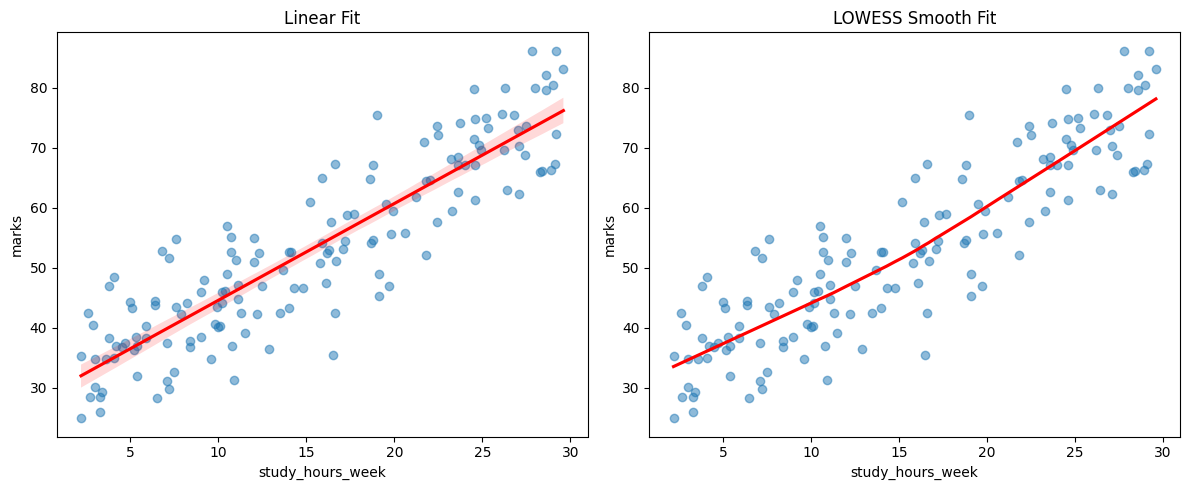

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.regplot(
    data=df, x='study_hours_week', y='marks',
    scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'}, ax=axes[0]
)
axes[0].set_title('Linear Fit')

sns.regplot(
    data=df, x='study_hours_week', y='marks', lowess=True, ci=None,
    scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'}, ax=axes[1]
)
axes[1].set_title('LOWESS Smooth Fit')

plt.tight_layout()
fig.savefig('coaching_lowess.png', bbox_inches='tight')
plt.show()

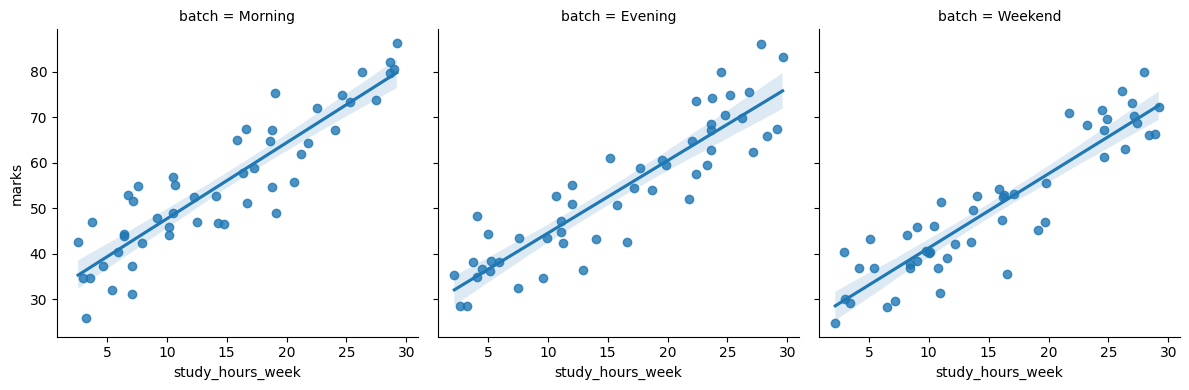

In [8]:
g = sns.lmplot(data=df, x='study_hours_week', y='marks', col='batch', height=4, aspect=1)
g.savefig('coaching_lmplot_batches.png')
plt.show()

Slope of Marks vs Attendance per Batch:
      batch  slope
0  Evening -0.151
1  Morning  0.216
2  Weekend  0.279


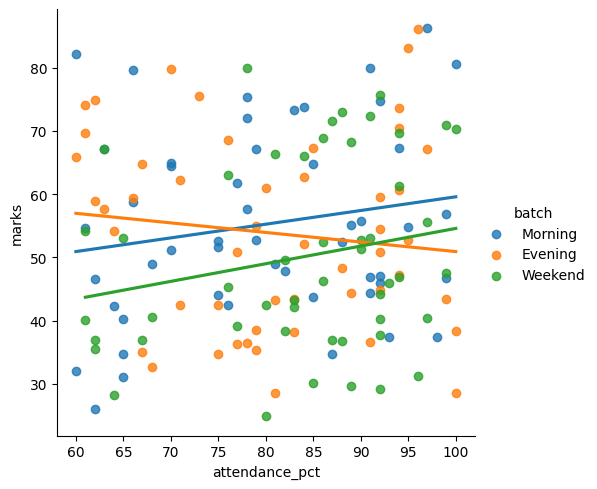

In [9]:
slopes = []
for batch_name, group in df.groupby('batch'):
    m, _ = np.polyfit(group['attendance_pct'], group['marks'], 1)
    slopes.append({'batch': batch_name, 'slope': round(m, 3)})

slope_df = pd.DataFrame(slopes)
print("Slope of Marks vs Attendance per Batch:\n", slope_df)

g = sns.lmplot(data=df, x='attendance_pct', y='marks', hue='batch', ci=None)
g.savefig('coaching_attendance_final.png')
plt.show()

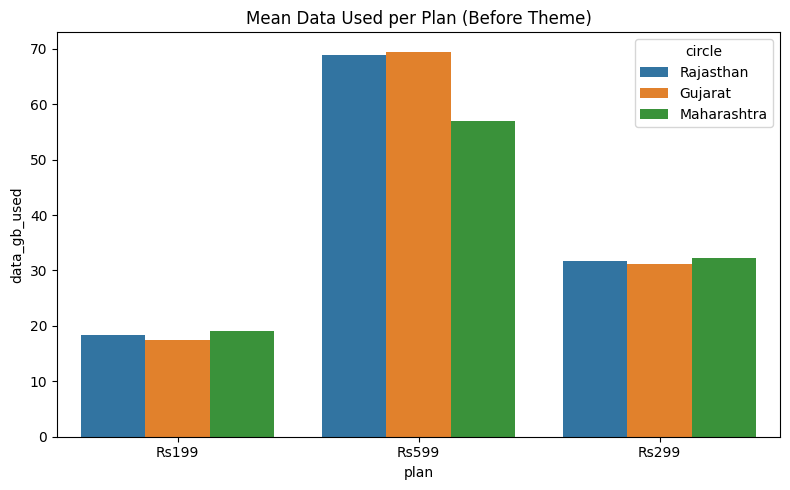

In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

n = 300
circle = np.random.choice(['Gujarat', 'Maharashtra', 'Rajasthan'], size=n)
plan = np.random.choice(['Rs199', 'Rs299', 'Rs599'], size=n, p=[0.5, 0.3, 0.2])

mean_map = {'Rs199': 18, 'Rs299': 32, 'Rs599': 60}
means = np.array([mean_map[p] for p in plan])
stds = means * 0.25

data_gb = np.round(np.maximum(np.random.normal(means, stds), 1), 1)
calls_min = np.round(np.maximum(np.random.normal(420, 120, size=n), 30)).astype(int)

df = pd.DataFrame({
    'user_id': range(1, n + 1),
    'circle': circle,
    'plan': plan,
    'data_gb_used': data_gb,
    'calls_min': calls_min
})

df.to_csv('recharge_usage.csv', index=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='plan', y='data_gb_used', hue='circle', errorbar=None)
plt.title('Mean Data Used per Plan (Before Theme)')
plt.tight_layout()
plt.savefig('recharge_before.png', bbox_inches='tight')
plt.show()

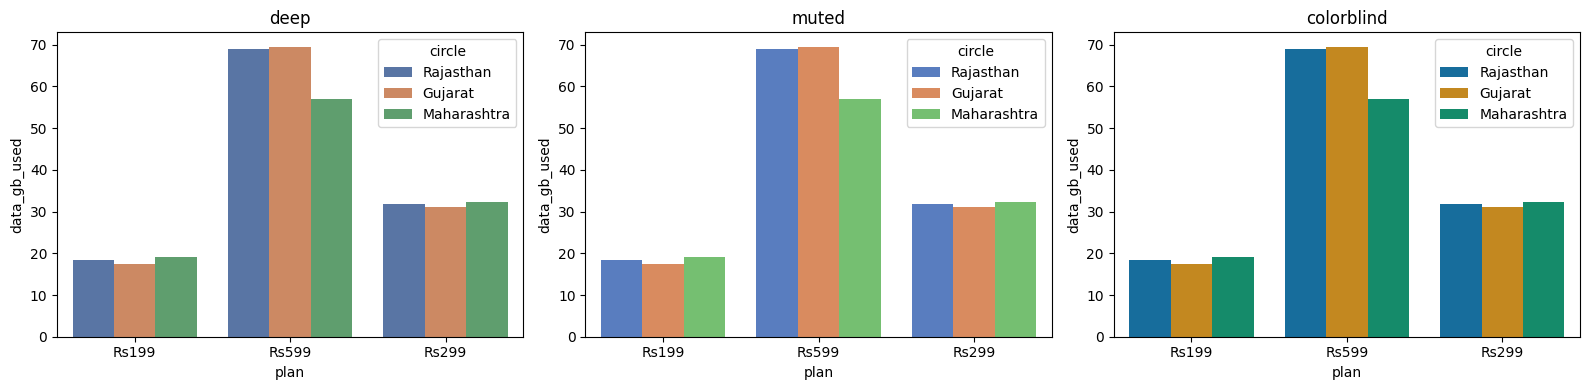

In [11]:
palettes = ['deep', 'muted', 'colorblind']
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, pal in zip(axes, palettes):
    sns.barplot(data=df, x='plan', y='data_gb_used', hue='circle',
                errorbar=None, palette=pal, ax=ax)
    ax.set_title(pal)

plt.tight_layout()
fig.savefig('recharge_palettes.png', bbox_inches='tight')
plt.show()

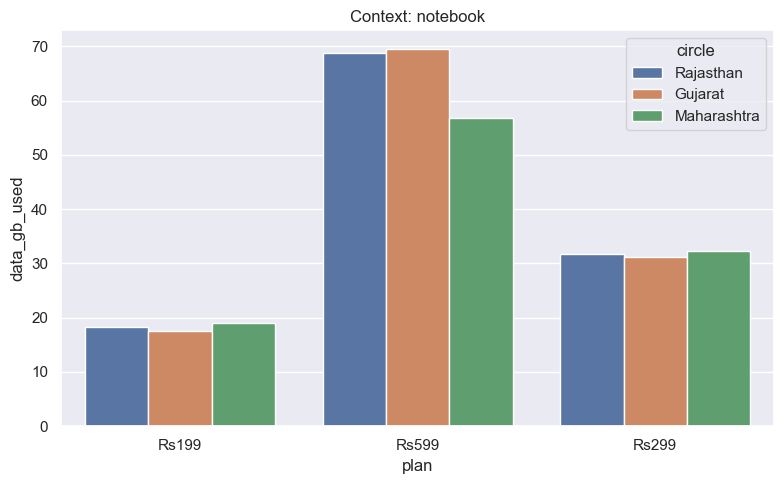

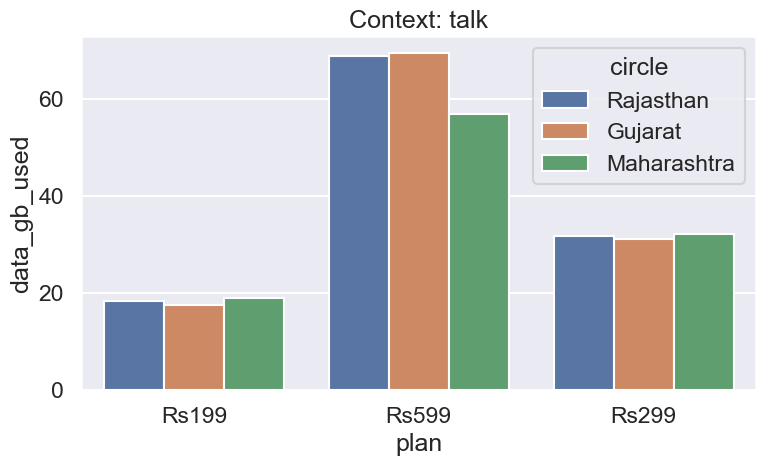

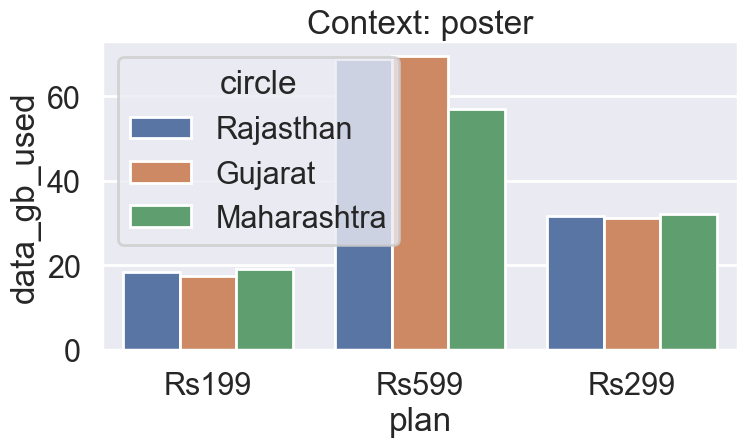

In [12]:
for ctx in ['notebook', 'talk', 'poster']:
    sns.set_theme()
    sns.set_context(ctx)
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(data=df, x='plan', y='data_gb_used', hue='circle', errorbar=None, ax=ax)
    ax.set_title(f'Context: {ctx}')
    plt.tight_layout()
    fig.savefig(f'recharge_{ctx}.png', bbox_inches='tight')
    plt.show()

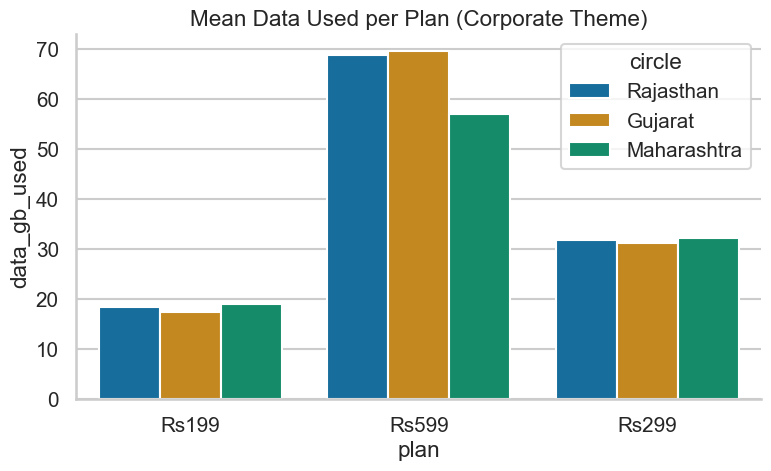

In [13]:
def apply_corporate_theme():
    sns.set_theme(
        style='whitegrid',
        context='talk',
        palette='colorblind',
        font_scale=0.9,
        rc={'axes.spines.top': False, 'axes.spines.right': False}
    )

apply_corporate_theme()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=df, x='plan', y='data_gb_used', hue='circle', errorbar=None, ax=ax)
ax.set_title('Mean Data Used per Plan (Corporate Theme)')
plt.tight_layout()
fig.savefig('recharge_corporate.png', bbox_inches='tight')
plt.show()